# Phase 2D | Multi-animal optogenetic data feasibility audit

**Primary:** DANDI **000009** — *Maintenance of persistent activity in a frontal thalamocortical loop* (mouse photoinhibition).  
**Backups (manifest-only):** DANDI **000005**, **000473**, **000253**.  
**Goal:** Verify, in **real** NWB recordings, whether *different animals* have both spike trains and reliable, time-aligned optogenetic events. Check optical units and assess whether animal-held-out neural-response modeling is feasible.

### Why this phase exists
DANDI 000568 gave us neural responses from **one** mouse; our previous light-aware models did not consistently outperform neural-only models. We need **independent-animal validation** before claiming biological generalization. This is a **data audit, not an ML training experiment**.

**Strict rules:**
- The `sub-*` directory is a **candidate biological subject**, not proof of independent mice. Check NWB subject IDs and publication metadata.
- A filename containing `+ogen` does **not** prove usable optical events or correct clock synchronization.
- A timestamp range overlap is **necessary but not sufficient** for precise synchronization.
- Never interpret uncalibrated raw optical codes as calibrated light intensity; report stored units exactly as found.
- Never call these recordings epilepsy or human data: these are non-epilepsy mouse circuit studies.
- **All output CSVs and figures must be generated from the actual Kaggle inspection.**

The original [Guo et al. (2017)](https://www.nature.com/articles/nature22324) study reports different cortical and thalamic photoinhibition protocols; do not assume every recording received the same light power or waveform. Protocol-to-file matching remains a separate validation step.

**Sources:** [DANDI 000009](https://dandiarchive.org/dandiset/000009), [DANDI 000005](https://dandiarchive.org/dandiset/000005), [DANDI 000473](https://dandiarchive.org/dandiset/000473), [DANDI 000253](https://dandiarchive.org/dandiset/000253), [DANDI 000009 study example](https://docs.dandiarchive.org/example-notebooks/000009/DataJoint/DJ-NWB-Guo-Inagaki-2017/notebooks/Guo-Inagaki-2017-examples/).

## 1 | Kaggle settings and download limits

**Settings:** Internet ON, **Accelerator = None** (CPU). No Kaggle Input required. The notebook queries public manifests and downloads a capped set of *small* `+ogen` NWB files. Do not remove the file-size and total-transfer safety limits during the first run.

In [1]:
import sys, os, json, zipfile, time, re, warnings, traceback
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone
from urllib.parse import urlparse

import requests
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

PRIMARY_ID = '000009'
VERSIONS = {
    '000009': '0.220126.1903',
    '000005': '0.220126.1853',
    '000473': '0.230417.1502',
    '000253': '0.240923.1441',
}
BASE = 'https://api.dandiarchive.org'
OUT = Path('/kaggle/working/phase2d_audit') if Path('/kaggle/working').exists() else Path('/mnt/data/phase2d_audit_local')
CACHE = OUT / '_cache'
OUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)

MAX_ASSET_MB = 8.0           # Never download files >8 MB in this initial audit
MAX_TOTAL_MB = 65.0          # Never download >65 MB total in this initial audit
MAX_SUBJECTS = 16            # Maximum different subject IDs to inspect
MAX_FILES_PER_SUBJECT = 2    # Try a fallback file if the first is unusable
MAX_FILES = 28
MAX_SERIES_SAMPLES = 1_000_000
MAX_SPIKE_SAMPLES = 1_000_000

SESSION = requests.Session()
retries = Retry(total=3, connect=3, read=2, backoff_factor=0.8,
                status_forcelist=[429, 500, 502, 503, 504], allowed_methods=['GET'])
SESSION.mount('https://', HTTPAdapter(max_retries=retries))
SESSION.headers.update({'Accept': 'application/json', 'User-Agent': 'Research-DANDI-Audit/0.1'})
print('Output:', OUT)
print('Limits: per file',MAX_ASSET_MB,'MB; total',MAX_TOTAL_MB,'MB; subjects',MAX_SUBJECTS)

Output: /kaggle/working/phase2d_audit
Limits: per file 8.0 MB; total 65.0 MB; subjects 16


## 2 | Audit complete published manifests (metadata only)

List all assets for four pinned datasets. Rank candidates by the number of **distinct subject folders with `+ogen` files that can be inspected cheaply**. These counts are **manifest-level**, not biological or synchronized-label verification.

In [2]:
def get_json(url):
    r = SESSION.get(url, timeout=(20,90), headers={'Accept':'application/json'})
    r.raise_for_status()
    return r.json()

def list_assets(did, version):
    url = f'{BASE}/api/dandisets/{did}/versions/{version}/assets/?page_size=100'
    rows = []
    for page in range(100):
        obj = get_json(url)
        if not isinstance(obj, dict) or 'results' not in obj:
            raise RuntimeError(f'Unexpected DANDI API payload for {did}: {str(obj)[:200]}')
        rows.extend(obj['results'])
        url = obj.get('next')
        if not url:
            break
    else:
        raise RuntimeError('Pagination unexpectedly exceeded 100 pages')
    if not rows: raise ValueError('No assets for '+did)
    df = pd.DataFrame(rows)
    df['dataset_id'] = did
    df['version'] = version
    df['subject_folder'] = df['path'].str.extract(r'(sub-[^/]+)', expand=False)
    df['file_bytes'] = pd.to_numeric(df['size'], errors='coerce')
    df['file_MB'] = df['file_bytes'] / 1e6
    df['is_nwb'] = df['path'].str.endswith('.nwb', na=False)
    df['is_ogen_path'] = df['path'].str.contains(r'\+ogen\.nwb$', regex=True, na=False)
    df['eligible_small_opto'] = df['is_nwb'] & df['is_ogen_path'] & df['file_bytes'].between(1, int(MAX_ASSET_MB * 1e6))
    return df

manifests, errors = {}, []
for did, version in VERSIONS.items():
    try:
        df = list_assets(did, version)
        manifests[did] = df
        df.to_csv(OUT / f'manifest_{did}.csv', index=False)
        print(did, 'files', len(df), 'subject folders', df.subject_folder.nunique(),
              '+ogen subject folders', df.loc[df.is_ogen_path,'subject_folder'].nunique(),
              'small +ogen files', int(df.eligible_small_opto.sum()))
    except Exception as exc:
        errors.append({'stage':'manifest','dataset_id':did,'path':'','error':repr(exc)})
        print('WARNING:', did, exc)

if PRIMARY_ID not in manifests:
    raise RuntimeError('Primary manifest unavailable: enable Kaggle Internet and rerun.')

screen = []
for did, df in manifests.items():
    screen.append({
        'dataset_id':did, 'version':VERSIONS[did], 'total_files':len(df),
        'subject_folders_in_manifest':df.subject_folder.nunique(),
        'opto_marked_files':int(df.is_ogen_path.sum()),
        'subjects_with_opto_marked_file':df.loc[df.is_ogen_path,'subject_folder'].nunique(),
        'small_opto_files':int(df.eligible_small_opto.sum()),
        'subjects_with_small_opto_file':df.loc[df.eligible_small_opto,'subject_folder'].nunique(),
        'min_opto_file_MB':df.loc[df.is_ogen_path,'file_MB'].min(),
        'total_archive_GB':df.file_bytes.sum()/1e9,
        'note':'Manifest presence alone does not confirm optical timestamps or neuronal spikes.'
    })
screen_df = pd.DataFrame(screen)
screen_df.to_csv(OUT/'dataset_manifest_screen.csv', index=False)
display(screen_df)

000009 files 173 subject folders 31 +ogen subject folders 27 small +ogen files 115
000005 files 148 subject folders 55 +ogen subject folders 43 small +ogen files 0
000473 files 25 subject folders 25 +ogen subject folders 25 small +ogen files 0
000253 files 98 subject folders 14 +ogen subject folders 0 small +ogen files 0


,dataset_id,version,total_files,subject_folders_in_manifest,opto_marked_files,subjects_with_opto_marked_file,small_opto_files,subjects_with_small_opto_file,min_opto_file_MB,total_archive_GB,note
0,000009,0.220126.1903,173,31,152,27,115,20,0.348280,12.919707,Manifest presence alone does not confirm optic...
1,000005,0.220126.1853,148,55,121,43,0,0,46.543184,46.436686,Manifest presence alone does not confirm optic...
2,000473,0.230417.1502,25,25,25,25,0,0,2912.287863,113.558681,Manifest presence alone does not confirm optic...
3,000253,0.240923.1441,98,14,0,0,0,0,NaN,679.753397,Manifest presence alone does not confirm optic...


## 3 | Select representative optogenetics files from different animals

Prioritize **one small `+ogen` file per subject**, then a second file as a fallback. The first-run limit is 16 distinct subject folders and 28 total files. This is a **screen**, not a census of all records.

In [3]:
primary = manifests[PRIMARY_ID]
eligible = primary.loc[primary.eligible_small_opto].copy()
if eligible.empty:
    raise RuntimeError('No small +ogen NWB assets found for primary dataset. Inspect manifest or use fallback dataset.')

# First pass: 1 file per subject; second pass: up to a second file if budget allows.
groups = {}
for sid, frame in eligible.groupby('subject_folder', sort=True):
    if not sid: continue
    groups[sid] = frame.sort_values(['file_MB', 'path']).head(MAX_FILES_PER_SUBJECT).to_dict('records')
subject_choices = sorted(groups, key=lambda s: (groups[s][0]['file_MB'], s))[:MAX_SUBJECTS]
choices = []
for pass_num in range(MAX_FILES_PER_SUBJECT):
    for subject in subject_choices:
        if len(groups[subject]) > pass_num:
            choices.append(groups[subject][pass_num])
choices = choices[:MAX_FILES]
selected = pd.DataFrame(choices)
selected.to_csv(OUT/'selected_small_opto_assets.csv',index=False)
print('Selected',len(selected),'files across', selected.subject_folder.nunique(), 'candidate animals.')
display(selected[['subject_folder','path','file_MB']].head(20))

Selected 28 files across 16 candidate animals.


,subject_folder,path,file_MB
0,sub-anm00260490,sub-anm00260490/sub-anm00260490_ses-20170627T0...,0.348280
1,sub-anm00264942,sub-anm00264942/sub-anm00264942_ses-20170627T0...,0.438196
2,sub-anm00323634,sub-anm00323634/sub-anm00323634_ses-20170627T0...,0.459732
3,sub-anm00260488,sub-anm00260488/sub-anm00260488_ses-20170627T0...,0.504116
4,sub-anm00264944,sub-anm00264944/sub-anm00264944_ses-20170627T0...,0.564544
5,sub-anm00264941,sub-anm00264941/sub-anm00264941_ses-20170627T0...,0.569408
6,sub-anm00322805,sub-anm00322805/sub-anm00322805_ses-20170627T0...,0.570932
7,sub-anm00267975,sub-anm00267975/sub-anm00267975_ses-20170627T0...,0.578312
8,sub-anm00239123,sub-anm00239123/sub-anm00239123_ses-20170627T0...,0.587240
9,sub-anm00264943,sub-anm00264943/sub-anm00264943_ses-20170627T0...,0.595004


## 4 | Download selected small files with strict byte caps

The program refuses downloads above the published size cap and aborts the transfer if the server sends too much. A failed download is logged and does not block other candidates.

In [4]:
def download_asset(row):
    nbytes = int(row['file_bytes'])
    if not (str(row['path']).endswith('.nwb') and bool(row['is_ogen_path'])):
        raise ValueError('Not an explicitly optogenetics-marked NWB asset')
    if nbytes > MAX_ASSET_MB*1e6 or nbytes < 1:
        raise ValueError('Refusing file outside per-asset size cap')
    filename = f"{row['asset_id']}.nwb"
    target = CACHE / filename
    if target.exists() and target.stat().st_size == nbytes:
        return target, 0
    partial = CACHE / (filename + '.part')
    count = 0
    try:
        with SESSION.get(f"{BASE}/api/assets/{row['asset_id']}/download/",
                         stream=True, timeout=(30,150), headers={'Accept':'*/*'}) as response:
            response.raise_for_status()
            with open(partial,'wb') as handle:
                for block in response.iter_content(chunk_size=1024*256):
                    if not block: continue
                    count += len(block)
                    if count > nbytes+16384 or count > MAX_ASSET_MB*1e6:
                        raise RuntimeError('Download exceeded file-size limit')
                    handle.write(block)
        if partial.stat().st_size != nbytes:
            raise IOError(f'Download size mismatch: expected={nbytes} got={partial.stat().st_size}')
        partial.replace(target)
        return target, count
    finally:
        if partial.exists():partial.unlink()

cached = {}
bytes_downloaded = 0
for i,row in enumerate(choices):
    if bytes_downloaded + int(row['file_bytes']) > MAX_TOTAL_MB*1e6:
        print('Stopped: maximum download budget reached.')
        break
    try:
        path, transferred = download_asset(row)
        bytes_downloaded += transferred
        cached[row['asset_id']] = path
        print(f"[{i+1}/{len(choices)}] {row['subject_folder']}: {path.stat().st_size/1e6:.2f} MB")
    except Exception as exc:
        errors.append({'stage':'download','dataset_id':PRIMARY_ID,'path':row['path'],'error':repr(exc)})
        print('Download warning:', str(row['path']).split('/')[-1],repr(exc))
print('Downloaded/cached',len(cached),'files; transferred',round(bytes_downloaded/1e6,2),'MB.')
if not cached: print('WARNING: no files downloaded. Examine network error CSV after export.')

[1/28] sub-anm00260490: 0.35 MB
[2/28] sub-anm00264942: 0.44 MB
[3/28] sub-anm00323634: 0.46 MB
[4/28] sub-anm00260488: 0.50 MB
[5/28] sub-anm00264944: 0.56 MB
[6/28] sub-anm00264941: 0.57 MB
[7/28] sub-anm00322805: 0.57 MB
[8/28] sub-anm00267975: 0.58 MB
[9/28] sub-anm00239123: 0.59 MB
[10/28] sub-anm00264943: 0.60 MB
[11/28] sub-anm00322807: 0.61 MB
[12/28] sub-anm00260487: 0.61 MB
[13/28] sub-anm00279338: 0.70 MB
[14/28] sub-anm00261335: 0.71 MB
[15/28] sub-anm00261334: 0.79 MB
[16/28] sub-anm00313106: 0.84 MB
[17/28] sub-anm00260490: 0.60 MB
[18/28] sub-anm00264942: 0.48 MB
[19/28] sub-anm00323634: 0.59 MB
[20/28] sub-anm00260488: 0.85 MB
[21/28] sub-anm00264944: 0.63 MB
[22/28] sub-anm00322805: 0.80 MB
[23/28] sub-anm00267975: 0.65 MB
[24/28] sub-anm00239123: 0.73 MB
[25/28] sub-anm00264943: 0.77 MB
[26/28] sub-anm00322807: 0.71 MB
[27/28] sub-anm00260487: 0.67 MB
[28/28] sub-anm00279338: 0.91 MB
Downloaded/cached 28 files; transferred 17.86 MB.


## 5 | Inspect real spike trains, optical series and timestamps

Read NWB files using `h5py` without loading raw voltage arrays. Extract:

- **Units:** sorted spike train counts and time span (only if actual `spike_times` exists).
- **OptogeneticSeries:** timestamps, raw stimulation codes, recorded units, complete ON→OFF transitions.
- **Time overlap:** fraction of inferred pulse onsets inside the spike time range (a **sanity check**, not proof of clock sync).
- **Subjects:** check subject ID stored in NWB against the parent `sub-*` folder.

If a file has no usable pulses or no spike trains, it is **not** marked model-ready. Never reconstruct missing labels from filenames.

In [5]:
def as_text(v):
    if isinstance(v,bytes): return v.decode('utf8','replace')
    if isinstance(v,np.ndarray):
        if v.ndim==0:return as_text(v[()])
        if v.size==1:return as_text(v.reshape(-1)[0])
        return '|'.join(map(as_text,v[:8]))
    return str(v)

def small_value(dset):
    try: return as_text(dset[()])
    except Exception: return ''

def collect_series(hf):
    found=[]
    def visitor(name, obj):
        if not isinstance(obj,h5py.Group) or 'data' not in obj: return
        ntype=as_text(obj.attrs.get('neurodata_type',''))
        path_lower=name.lower()
        if ('optogeneticseries' in ntype.lower() or
            ('stimulus' in path_lower and any(w in path_lower for w in ['opto','photo','laser','light']))):
            found.append(name)
    hf.visititems(visitor)
    return found

def inspect_series(hf, path):
    g=hf[path]
    data=g['data']
    n = int(data.shape[0]) if data.ndim else 1
    ts=g.get('timestamps')
    unit=as_text(data.attrs.get('unit', g.attrs.get('unit', 'NOT_RECORDED')))
    base={'series_path':path,'data_points':n,'reported_unit':unit,
          'raw_values_preview':'','n_complete_positive_to_zero_intervals':0,
          'median_duration_ms':np.nan,'onset_span_sec':'','series_inspection':'',
          'timestamp_span_sec':'','scan_complete':False}
    pulses=[]
    if ts is None:
        base['series_inspection']='No explicit timestamps; cannot infer pulse ON/OFF transitions safely'
        return base,pulses
    if len(ts.shape)!=1 or len(data.shape)!=1 or len(ts)!=n or n<2:
        base['series_inspection']='Unsupported or inconsistent timestamps/data shapes'
        return base,pulses
    if n>MAX_SERIES_SAMPLES:
        base['series_inspection']='Timeseries too large for bounded scan; event count unverified'
        return base,pulses
    t=np.asarray(ts[:],dtype=np.float64)
    v=np.asarray(data[:],dtype=np.float64)
    if not(np.all(np.isfinite(t)) and np.all(np.diff(t)>=0)):
        base['series_inspection']='Nonfinite or unsorted timestamp values'
        return base,pulses
    base['scan_complete']=True
    base['timestamp_span_sec']=f'{t[0]:.3f} .. {t[-1]:.3f}'
    finite=np.isfinite(v)
    raw=np.unique(v[finite])
    base['raw_values_preview']='|'.join(f'{x:.6g}' for x in raw[:16])
    if not len(raw) or not np.any(v==0) or not np.any(v>0):
        base['series_inspection']='No positive-and-zero states; NOT a verified pulse ON/OFF series'
        return base,pulses
    active=finite & (v>0)
    start=np.flatnonzero(active & np.r_[True,~active[:-1]])
    end=np.flatnonzero(~active & np.r_[False,active[:-1]])
    if len(start) and start[0]==0:start=start[1:]
    for b in start:
        idx=np.searchsorted(end,b,side='right')
        if idx==len(end):continue
        e=end[idx]
        if t[e]<=t[b]:continue
        pulses.append({'series_path':path,'onset_sec':float(t[b]),'offset_sec':float(t[e]),
                       'duration_ms':float((t[e]-t[b])*1000),'raw_code':float(v[b]),'stored_unit':unit})
    base['n_complete_positive_to_zero_intervals']=len(pulses)
    if pulses:
        durations=[p['duration_ms'] for p in pulses]
        base['median_duration_ms']=float(np.median(durations))
        base['onset_span_sec']=f"{pulses[0]['onset_sec']:.3f} .. {pulses[-1]['onset_sec']:.3f}"
        base['series_inspection']='Candidate complete ON/OFF transitions; timing needs experimental verification'
    else:
        base['series_inspection']='Positive/zero values found, but no complete ON/OFF transitions'
    return base,pulses

def unit_group(hf):
    u=hf.get('/units')
    if isinstance(u,h5py.Group) and 'spike_times' in u:return u
    found=[]
    def visitor(name,obj):
        if isinstance(obj,h5py.Group) and 'spike_times' in obj and 'spike_times_index' in obj:
            found.append((name,obj))
    hf.visititems(visitor)
    return found[0][1] if found else None

def inspect_spikes(hf):
    u=unit_group(hf)
    if u is None:return {'units':0,'spikes':0,'min_spike_sec':np.nan,'max_spike_sec':np.nan,
                         'spike_scan':'Not found'}, []
    d=u.get('spike_times')
    if not isinstance(d,h5py.Dataset) or d.ndim!=1:
        return {'units':0,'spikes':0,'min_spike_sec':np.nan,'max_spike_sec':np.nan,
                'spike_scan':'No 1D spike_times dataset'}, []
    n=int(d.shape[0])
    ids=u.get('id')
    idx=u.get('spike_times_index')
    n_units=int(ids.shape[0]) if isinstance(ids,h5py.Dataset) else (int(idx.shape[0]) if isinstance(idx,h5py.Dataset) else 0)
    if n==0:return {'units':n_units,'spikes':0,'min_spike_sec':np.nan,'max_spike_sec':np.nan,'spike_scan':'Empty'}, []
    # Download only the actual spike-time column; never touch raw ephys waveforms.
    if n<=MAX_SPIKE_SAMPLES:
        times=np.asarray(d[:],dtype=float)
        mode='all spike times'
    else:
        stride=max(1,n//MAX_SPIKE_SAMPLES)
        times=np.asarray(d[::stride],dtype=float)
        mode='subsampled spike times (approximate extent)'
    times=times[np.isfinite(times)]
    tmin,tmax=(float(np.min(times)),float(np.max(times))) if len(times) else (np.nan,np.nan)
    return {'units':n_units,'spikes':n,'min_spike_sec':tmin,'max_spike_sec':tmax,'spike_scan':mode}, times[:10000].tolist()

def audit_nwb(path, row):
    sid=row['subject_folder']
    base={'dataset_id':PRIMARY_ID,'version':VERSIONS[PRIMARY_ID],
          'asset_id':row['asset_id'],'path':row['path'], 'subject_folder':sid,
          'subject_nwb':'','subject_consistency':'unverified', 'n_opto_series':0,
          'n_completed_pulse_intervals':0,'n_units':0,'n_spikes':0,
          'spike_min_sec':np.nan,'spike_max_sec':np.nan,
          'pulse_inside_spike_fraction':np.nan,'first_usable_pulse_sec':np.nan,
          'recorded_stim_units':'','has_paired_units_and_pulses':False,
          'plausible_time_overlap':False,'caution':'Time overlap is not proof of synchronization'}
    with h5py.File(path,'r') as hf:
        sub=hf.get('/general/subject/subject_id')
        if isinstance(sub,h5py.Dataset):
            subval=small_value(sub)
            base['subject_nwb']=subval
            norm=lambda s:as_text(s).lower().removeprefix('sub-')
            base['subject_consistency']=('match' if norm(subval)==norm(sid) else 'MISMATCH')
        unit, sample_spikes=inspect_spikes(hf)
        base['n_units']=unit['units'];base['n_spikes']=unit['spikes']
        base['spike_min_sec']=unit['min_spike_sec'];base['spike_max_sec']=unit['max_spike_sec']
        series=collect_series(hf)
        base['n_opto_series']=len(series)
        logs,pulses=[],[]
        for name in series:
            summ, events = inspect_series(hf,name)
            summ.update({'asset_id':row['asset_id'],'subject_folder':sid,'path':row['path']})
            logs.append(summ)
            pulses.extend(events)
        base['n_completed_pulse_intervals']=len(pulses)
        base['recorded_stim_units']='|'.join(sorted(set(p['stored_unit'] for p in pulses)))
        for p in pulses:p.update({'asset_id':row['asset_id'],'subject_folder':sid,'file_path':row['path']})
        if pulses:
            base['first_usable_pulse_sec']=float(min(p['onset_sec'] for p in pulses))
        if (pulses and unit['spikes']>0 and np.isfinite(unit['min_spike_sec']) and
              np.isfinite(unit['max_spike_sec'])):
            within=sum(unit['min_spike_sec'] <= p['onset_sec'] <= unit['max_spike_sec'] for p in pulses)
            base['pulse_inside_spike_fraction']=within/len(pulses)
            base['plausible_time_overlap']=within/len(pulses)>=0.9
            base['has_paired_units_and_pulses']= (unit['units']>0 and len(pulses)>=3 and
                                                  base['plausible_time_overlap'])
    return base,logs,pulses

asset_rows, series_rows, pulse_rows=[],[],[]
for row in choices:
    file=cached.get(row['asset_id'])
    if file is None:continue
    try:
        base,series,pulses=audit_nwb(file,row)
        asset_rows.append(base);series_rows.extend(series);pulse_rows.extend(pulses)
        print(f"{row['subject_folder']}: units={base['n_units']}, optical series={base['n_opto_series']}, "
              f"complete pulses={base['n_completed_pulse_intervals']}, time overlap={base['pulse_inside_spike_fraction']}")
    except Exception as exc:
        errors.append({'stage':'inspect','dataset_id':PRIMARY_ID,'path':row['path'],'error':repr(exc)})
        print('Inspection WARNING:',row['path'],repr(exc))

assets_df=pd.DataFrame(asset_rows)
series_df=pd.DataFrame(series_rows)
pulses_df=pd.DataFrame(pulse_rows)
assets_df.to_csv(OUT/'real_nwb_joint_asset_audit.csv',index=False)
series_df.to_csv(OUT/'optogenetic_series_and_units.csv',index=False)
pulses_df.to_csv(OUT/'observed_candidate_pulses.csv',index=False)
display(assets_df)

sub-anm00260490: units=3, optical series=0, complete pulses=0, time overlap=nan
sub-anm00264942: units=3, optical series=0, complete pulses=0, time overlap=nan
sub-anm00323634: units=11, optical series=0, complete pulses=0, time overlap=nan
sub-anm00260488: units=5, optical series=0, complete pulses=0, time overlap=nan
sub-anm00264944: units=10, optical series=0, complete pulses=0, time overlap=nan
sub-anm00264941: units=8, optical series=0, complete pulses=0, time overlap=nan
sub-anm00322805: units=9, optical series=0, complete pulses=0, time overlap=nan
sub-anm00267975: units=16, optical series=0, complete pulses=0, time overlap=nan
sub-anm00239123: units=4, optical series=0, complete pulses=0, time overlap=nan
sub-anm00264943: units=18, optical series=0, complete pulses=0, time overlap=nan
sub-anm00322807: units=27, optical series=0, complete pulses=0, time overlap=nan
sub-anm00260487: units=9, optical series=0, complete pulses=0, time overlap=nan
sub-anm00279338: units=20, optical 

,dataset_id,version,asset_id,path,subject_folder,subject_nwb,subject_consistency,n_opto_series,n_completed_pulse_intervals,n_units,n_spikes,spike_min_sec,spike_max_sec,pulse_inside_spike_fraction,first_usable_pulse_sec,recorded_stim_units,has_paired_units_and_pulses,plausible_time_overlap,caution
0,000009,0.220126.1903,aea47d9d-5331-4ac9-a6a9-87435ac02c0b,sub-anm00260490/sub-anm00260490_ses-20170627T0...,sub-anm00260490,anm00260490,match,0,0,3,9004,1266.128984,3217.040155,NaN,NaN,,False,False,Time overlap is not proof of synchronization
1,000009,0.220126.1903,8ce1a50f-11bd-4a75-a510-64c3f32bb529,sub-anm00264942/sub-anm00264942_ses-20170627T0...,sub-anm00264942,anm00264942,match,0,0,3,19537,458.143196,2722.620388,NaN,NaN,,False,False,Time overlap is not proof of synchronization
2,000009,0.220126.1903,4135ca35-fcdd-40e3-9b24-d912dff9f2fe,sub-anm00323634/sub-anm00323634_ses-20170627T0...,sub-anm00323634,anm00323634,match,0,0,11,21342,318.748681,2310.382292,NaN,NaN,,False,False,Time overlap is not proof of synchronization
3,000009,0.220126.1903,475e61ba-ca60-4c7a-80cc-1d954ce5d6af,sub-anm00260488/sub-anm00260488_ses-20170627T0...,sub-anm00260488,anm00260488,match,0,0,5,26262,2130.421806,4908.104065,NaN,NaN,,False,False,Time overlap is not proof of synchronization
4,000009,0.220126.1903,e3eafe27-c7e9-45de-aa58-4e95eaf7f2cf,sub-anm00264944/sub-anm00264944_ses-20170627T0...,sub-anm00264944,anm00264944,match,0,0,10,32005,2025.004578,4378.523917,NaN,NaN,,False,False,Time overlap is not proof of synchronization
5,000009,0.220126.1903,a174504d-3fbe-4171-b3a9-df2ee2637f4d,sub-anm00264941/sub-anm00264941_ses-20170627T0...,sub-anm00264941,anm00264941,match,0,0,8,31029,3232.476160,5188.809703,NaN,NaN,,False,False,Time overlap is not proof of synchronization
6,000009,0.220126.1903,754d3364-4944-477c-b626-c94ab5d119d0,sub-anm00322805/sub-anm00322805_ses-20170627T0...,sub-anm00322805,anm00322805,match,0,0,9,34039,699.864472,2468.293085,NaN,NaN,,False,False,Time overlap is not proof of synchronization
7,000009,0.220126.1903,b69b65f9-a02e-4745-9dac-b5a0b4459871,sub-anm00267975/sub-anm00267975_ses-20170627T0...,sub-anm00267975,anm00267975,match,0,0,16,34107,2375.132479,4757.211841,NaN,NaN,,False,False,Time overlap is not proof of synchronization
8,000009,0.220126.1903,092550fe-91d3-4585-a097-8517a8d7657e,sub-anm00239123/sub-anm00239123_ses-20170627T0...,sub-anm00239123,anm00239123,match,0,0,4,34057,1498.888201,5203.948925,NaN,NaN,,False,False,Time overlap is not proof of synchronization
9,000009,0.220126.1903,38c14d24-4986-43b6-beb6-38aca0b6e920,sub-anm00264943/sub-anm00264943_ses-20170627T0...,sub-anm00264943,anm00264943,match,0,0,18,39514,1261.543478,3406.581702,NaN,NaN,,False,False,Time overlap is not proof of synchronization


## 6 | Independent-mouse feasibility report

**Critical:** The report counts distinct validated *subject folders* with one or more recordings containing sorted units + complete optical ON/OFF transitions in approximately overlapping time ranges. We do **not** treat multiple sessions, cells, windows, or pulses as independent animals. Subject-ID mismatches fail the audit.

In [6]:
if assets_df.empty:
    by_subject=pd.DataFrame()
    valid_subject_count=0
else:
    assets_df['safe_subject_id'] = assets_df['subject_consistency'].eq('match')
    assets_df['provisionally_usable']=(assets_df['has_paired_units_and_pulses'] &
                                      assets_df['safe_subject_id'])
    assets_df.to_csv(OUT/'real_nwb_joint_asset_audit.csv',index=False)
    by_subject=assets_df.groupby('subject_folder',as_index=False).agg(
        checked_files=('asset_id','count'),
        files_with_units=('n_units',lambda x:int((x>0).sum())),
        files_with_pulses=('n_completed_pulse_intervals',lambda x:int((x>0).sum())),
        files_usable=('provisionally_usable','sum'),
        total_pulse_intervals=('n_completed_pulse_intervals','sum'),
        nwb_subject_consistent=('safe_subject_id','all'),
        max_units=('n_units','max'))
    by_subject['provisionally_usable_animal']=by_subject.files_usable>0
    valid_subject_count=int(by_subject.provisionally_usable_animal.sum())
by_subject.to_csv(OUT/'joint_opto_neural_subject_summary.csv',index=False)
print('SUBJECT IDS WITH CANDIDATE JOINT DATA (timing provisional):',valid_subject_count)
display(by_subject)

if valid_subject_count>=5:
    decision='PROMISING: At least five candidate independent animals have spike+optical timing overlap. Proceed to protocol validation, artifact checks, and animal-held-out modeling.'
elif valid_subject_count>=2:
    decision='PARTIAL: More than one animal has candidate paired records, but increase independent-animal coverage before model training.'
else:
    decision='NOT READY: Insufficient animals with proven paired spike+optical events in inspected files. Investigate more files or alternative Dandisets.'
print('ASSESSMENT:',decision)
print('WARNING: No calibrated optical-dose claim and no clinical epilepsy conclusion can be made from this audit.')

SUBJECT IDS WITH CANDIDATE JOINT DATA (timing provisional): 0


,subject_folder,checked_files,files_with_units,files_with_pulses,files_usable,total_pulse_intervals,nwb_subject_consistent,max_units,provisionally_usable_animal
0,sub-anm00239123,2,2,0,0,0,True,6,False
1,sub-anm00260487,2,2,0,0,0,True,9,False
2,sub-anm00260488,2,2,0,0,0,True,14,False
3,sub-anm00260490,2,2,0,0,0,True,6,False
4,sub-anm00261334,1,1,0,0,0,True,5,False
5,sub-anm00261335,1,1,0,0,0,True,12,False
6,sub-anm00264941,1,1,0,0,0,True,8,False
7,sub-anm00264942,2,2,0,0,0,True,16,False
8,sub-anm00264943,2,2,0,0,0,True,18,False
9,sub-anm00264944,2,2,0,0,0,True,20,False


ASSESSMENT: NOT READY: Insufficient animals with proven paired spike+optical events in inspected files. Investigate more files or alternative Dandisets.


## 7 | Grounded visual diagnostics

These figures are created **only if** real Kaggle data exist. They are dataset-availability checks, *not* model-performance plots or causal effects.

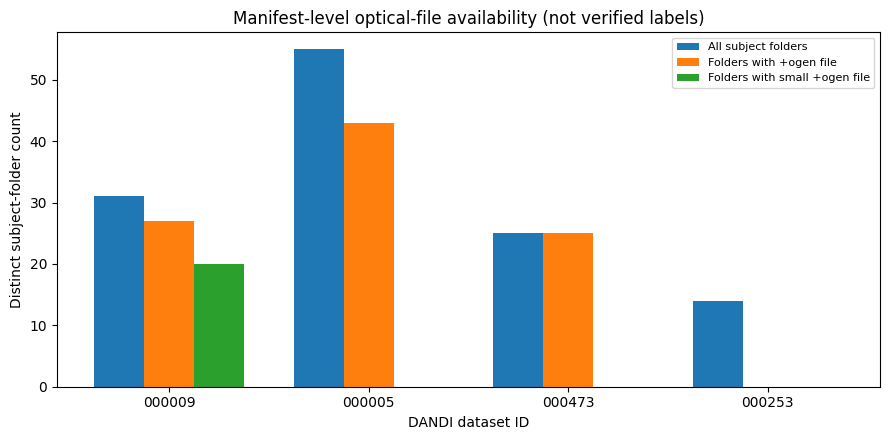

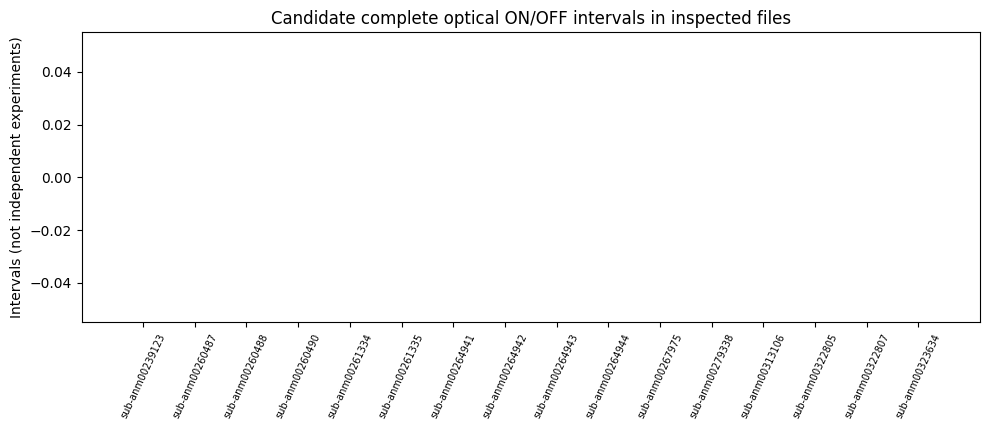

In [7]:
# Figure 1: manifest coverage by dataset.
if not screen_df.empty:
    fig,ax=plt.subplots(figsize=(9,4.5))
    x=np.arange(len(screen_df))
    ax.bar(x-0.25,screen_df['subject_folders_in_manifest'],width=0.25,label='All subject folders')
    ax.bar(x,screen_df['subjects_with_opto_marked_file'],width=0.25,label='Folders with +ogen file')
    ax.bar(x+0.25,screen_df['subjects_with_small_opto_file'],width=0.25,label='Folders with small +ogen file')
    ax.set_xticks(x,screen_df.dataset_id.tolist());ax.set_ylabel('Distinct subject-folder count')
    ax.set_xlabel('DANDI dataset ID');ax.set_title('Manifest-level optical-file availability (not verified labels)')
    ax.legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/'fig1_manifest_subject_coverage.png',dpi=170)
    plt.show()

# Figure 2: confirmed joint data by subject.
if not by_subject.empty:
    fig,ax=plt.subplots(figsize=(10,4.4))
    sorted_subject=by_subject.sort_values('total_pulse_intervals',ascending=False)
    ax.bar(sorted_subject.subject_folder,sorted_subject.total_pulse_intervals)
    ax.set_title('Candidate complete optical ON/OFF intervals in inspected files')
    ax.set_ylabel('Intervals (not independent experiments)')
    ax.tick_params(axis='x',rotation=65,labelsize=7)
    fig.tight_layout();fig.savefig(OUT/'fig2_recorded_pulses_by_subject.png',dpi=170);plt.show()

## 8 | Export ZIP and verdict

The result archive includes complete manifest counts, exactly which NWB assets were inspected, optical series summaries, candidate pulses, biological subject checks, the full error log, and figure PNGs. **Do not include cached NWB files in the ZIP** (the ZIP should remain small). Download `phase2d_multi_animal_audit_results.zip` and upload it back to ChatGPT for a careful scientific review.

In [8]:
err_df=pd.DataFrame(errors,columns=['stage','dataset_id','path','error'])
err_df.to_csv(OUT/'audit_errors.csv',index=False)

summary={
    'date_utc':datetime.now(timezone.utc).isoformat(),
    'primary_dandiset':PRIMARY_ID,'pinned_version':VERSIONS[PRIMARY_ID],
    'files_selected':int(len(selected)), 'files_downloaded_or_cached':len(cached),
    'files_inspected':len(assets_df),'candidate_joint_subjects':int(valid_subject_count),
    'actual_spike_opto_series_join_test':'completed where data available',
    'classification':'pilot dataset suitability assessment - NOT clinical validation',
    'verdict':decision,'errors':len(errors),
    'limitations':[ 'Subfolder IDs need publication-level biological independence confirmation',
        'Pulse-positive transitions may not encode real delivered light without protocol verification',
        'Timestamp overlap is not proof of precise clock synchronization',
        'Calibrated optical dose may be unavailable',
        'This is mouse thalamocortical, not human epilepsy physiology' ]
}
(OUT/'phase2d_feasibility_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
(OUT/'HOW_TO_INTERPRET_RESULTS.txt').write_text(
    'DANDI 000009 - Phase 2D independent-animal data audit\n\n'
    +decision+'\n\n'
    +'Pass 1: Manifest subject folders with +ogen are only CANDIDATES.\n'
    +'Pass 2: h5py inspects spike_times and optical timestamps/data.\n'
    +'Pass 3: Files are provisionally usable only when units + complete ON/OFF intervals '
    +'co-occur, their timestamps overlap, and subject IDs match.\n'
    +'Confirm real optogenetic protocols, timing offset/TTL, dose, and independent mice '
    +'before training or claiming cross-animal performance.\n'
    +'Optical codes should not be assumed to be physical watts.\n',encoding='utf-8')
zip_path=OUT.parent/'phase2d_multi_animal_audit_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.iterdir()):
        if f.is_file() and f.suffix.lower() in {'.csv','.json','.txt','.png'}:
            z.write(f,arcname=f.name)
print('RESULT ZIP:',zip_path,'MB:',round(zip_path.stat().st_size/1e6,2))
print('Upload this ZIP for our next scientific decision.')

RESULT ZIP: /kaggle/working/phase2d_multi_animal_audit_results.zip MB: 0.15
Upload this ZIP for our next scientific decision.
